# Chapter 31: Skips and normalisation

Checks [chapter 31](../../book/31-skips-and-normalisation.md). The models are exactly the ones the theorems are about:
**plates** (a projection onto a unit axis, a linear map), a **bypass** (`light + plate(light)`), an **amplifier**
(`light / length`), and **residual layers** `input + branch(input)`. The branches in the slope experiments are
`slope * tanh(orthogonal matrix @ input)`, which has slope at most `slope` (an orthogonal matrix has gain 1, `tanh` has
slope at most 1); nothing is trained. Everything is NumPy in float64, seeded. These are measurements, not proofs: the
proofs are in `SkipAndNorm.lean` and `Residual.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, BOUND, MODEL, BEFORE

use_style()
DEEP = sns.color_palette("deep")
AMPLIFIER_COLOUR, CONTROL_COLOUR = DEEP[5], DEEP[3]
generator = np.random.default_rng(31)


def make_unit(vector):
    return vector / np.linalg.norm(vector)


def pass_through_plate(axis, light):
    return np.dot(axis, light) * axis


def pass_through_skip_plate(axis, light):
    return light + pass_through_plate(axis, light)


def renormalize(light):
    length = np.linalg.norm(light)
    return light / length if length > 0 else light


def make_random_orthogonal(dimension):
    matrix, upper = np.linalg.qr(generator.standard_normal((dimension, dimension)))
    return matrix * np.sign(np.diag(upper))


def add_skip(branch, state):
    return state + branch(state)

## Claim 1: a bypass adds three times the squared overlap (`norm_skipPlate_sq`, `norm_le_norm_skipPlate`)

The squared length after a plate with a bypass is the squared length before plus `3 * overlap^2`, for a unit axis, in
any dimension; so the light is never dimmed. Prediction: over 3000 random (axis, light) pairs in dimensions 2 to 8, the
two sides agree to rounding error and the length never falls. What would count against the claim: any pair where the
difference is larger than rounding, or where the length falls. The control breaks the hypothesis: an axis of length
1.5 instead of 1. The identity should then fail, by a large amount.

In [2]:
TRIAL_COUNT = 3000
worst_identity_error, worst_length_change, control_errors = 0.0, np.inf, []
for trial in range(TRIAL_COUNT):
    dimension = int(generator.integers(2, 9))
    axis = make_unit(generator.standard_normal(dimension))
    light = generator.standard_normal(dimension) * generator.uniform(0.1, 10)
    overlap = np.dot(axis, light)
    after = pass_through_skip_plate(axis, light)
    gap = abs(np.dot(after, after) - (np.dot(light, light) + 3 * overlap ** 2))
    worst_identity_error = max(worst_identity_error, gap / np.dot(light, light))
    worst_length_change = min(worst_length_change, np.linalg.norm(after) - np.linalg.norm(light))
    long_axis = 1.5 * axis
    long_overlap = np.dot(long_axis, light)
    long_after = pass_through_skip_plate(long_axis, light)
    control_errors.append(abs(np.dot(long_after, long_after) - (np.dot(light, light) + 3 * long_overlap ** 2)) / np.dot(light, light))

print(f"{TRIAL_COUNT} random (axis, light) pairs")
print(f"[by construction, cannot fail] squared length after a bypass plate = before + 3 overlap^2 (worst relative error {worst_identity_error:.1e}); the algebra of the formula, not counted as evidence")
print(f"[by construction, cannot fail] a bypass plate never shortens the light (smallest change in length {worst_length_change:+.1e}); follows from the identity, not counted as evidence")
report("control: an axis of length 1.5 breaks the identity", np.mean(control_errors) > 0.1,
       f"mean relative error {np.mean(control_errors):.2f}")

3000 random (axis, light) pairs
[by construction, cannot fail] squared length after a bypass plate = before + 3 overlap^2 (worst relative error 2.2e-15); the algebra of the formula, not counted as evidence
[by construction, cannot fail] a bypass plate never shortens the light (smallest change in length +6.8e-08); follows from the identity, not counted as evidence
[PASS] control: an axis of length 1.5 breaks the identity  (mean relative error 0.69)


True

## Claim 2: the hand example, and a crossed plate (`skipPlate_of_crossed`, `iterate_skipPlate_sub_plate`)

The chapter's example: light `(3, 4)`, axis `(1, 0)`. A bare plate gives `(3, 0)`; a bypass gives `(6, 4)`, then `(12, 4)`,
then `(24, 4)`: the along part doubles and the across part does not move. A crossed light `(0, 5)` is dark after a bare
plate and unchanged after a bypass plate. Prediction: exact equality, so the check fails on any difference.

In [3]:
axis = np.array([1.0, 0.0])
light = np.array([3.0, 4.0])
bare = pass_through_plate(axis, light)
light_after = [pass_through_skip_plate(axis, light)]
for repeat in range(2):
    light_after.append(pass_through_skip_plate(axis, light_after[-1]))
crossed = np.array([0.0, 5.0])
print(f"[by construction, cannot fail] bare plate: (3, 4) -> {bare}; hand arithmetic, not counted as evidence")
print("[by construction, cannot fail] bypass plate three times: " + " ".join(str(step) for step in light_after) + "; hand arithmetic, not counted as evidence")
print(f"[by construction, cannot fail] crossed light (0, 5): after a bare plate {pass_through_plate(axis, crossed)}, after a bypass plate {pass_through_skip_plate(axis, crossed)}; hand arithmetic, not counted as evidence")

[by construction, cannot fail] bare plate: (3, 4) -> [3. 0.]; hand arithmetic, not counted as evidence
[by construction, cannot fail] bypass plate three times: [6. 4.] [12.  4.] [24.  4.]; hand arithmetic, not counted as evidence
[by construction, cannot fail] crossed light (0, 5): after a bare plate [0. 0.], after a bypass plate [0. 5.]; hand arithmetic, not counted as evidence


## Claim 3: a plate and an amplifier turn the light without loss (`renorm_plate`, `throughNormedPlates_eq`, `renorm_plate_of_crossed`)

Light with a positive overlap with a unit axis comes out of plate and amplifier exactly along the axis. Stack 40 plates
in three dimensions, each axis turned less than a right angle from the last, with a random turn each time. Prediction: after
every plate the light has length 1 and equals the plate's axis. What would count against it: any length other than 1.
The chapter's amplifier example is also checked: axis `(0.6, 0.8)` and light `(1, 0)` give `(0.6, 0.8)`, while without
the amplifier the length is `0.6` after one plate and `0.36` after a second plate turned by the same angle again. The control is a crossed plate: the light goes
dark, and the amplifier does not revive it.

In [4]:
def make_turned_axis(previous_axis, largest_turn):
    while True:
        candidate = make_unit(previous_axis + generator.standard_normal(3) * generator.uniform(0.2, 3))
        turn = np.arccos(np.clip(np.dot(previous_axis, candidate), -1, 1))
        if 0.05 < np.dot(previous_axis, candidate) and turn < largest_turn:
            return candidate

axes = [make_unit(generator.standard_normal(3))]
for plate in range(40):
    axes.append(make_turned_axis(axes[-1], np.pi / 2 - 0.02))
light = axes[0]
worst_length_error, worst_direction_error = 0.0, 0.0
for axis in axes[1:]:
    light = renormalize(pass_through_plate(axis, light))
    worst_length_error = max(worst_length_error, abs(np.linalg.norm(light) - 1))
    worst_direction_error = max(worst_direction_error, np.linalg.norm(light - axis))
report("amplified stack: light equals the plate's axis after each of 40 plates",
       worst_direction_error < 1e-12, f"worst direction error {worst_direction_error:.1e}")
print(f"[by construction, cannot fail] the amplifier divides by the length, so the length is 1 (worst error {worst_length_error:.1e}); not counted as evidence")

axis = np.array([0.6, 0.8])
light = np.array([1.0, 0.0])
once = pass_through_plate(axis, light)
turned_axis = np.array([axis[0] * 0.6 - axis[1] * 0.8, axis[1] * 0.6 + axis[0] * 0.8])   # the axis turned by the same angle again
twice = pass_through_plate(turned_axis, once)
report("chapter example: amplified light is the axis; bare lengths 0.6 then 0.36",
       np.allclose(renormalize(once), axis) and np.isclose(np.linalg.norm(once), 0.6) and np.isclose(np.linalg.norm(twice), 0.36),
       f"lengths {np.linalg.norm(once):.2f}, {np.linalg.norm(twice):.2f}")

crossed_light = np.array([0.0, 1.0])
dark = renormalize(pass_through_plate(np.array([1.0, 0.0]), crossed_light))
report("control: a crossed plate leaves nothing for the amplifier to restore", np.linalg.norm(dark) == 0.0,
       f"length after plate and amplifier {np.linalg.norm(dark):.1f}")

[PASS] amplified stack: light equals the plate's axis after each of 40 plates  (worst direction error 2.5e-16)
[by construction, cannot fail] the amplifier divides by the length, so the length is 1 (worst error 2.2e-16); not counted as evidence
[PASS] chapter example: amplified light is the axis; bare lengths 0.6 then 0.36  (lengths 0.60, 0.36)
[PASS] control: a crossed plate leaves nothing for the amplifier to restore  (length after plate and amplifier 0.0)


True

## Figure: the length of the light through a stack of plates

Plates whose axes each turn 0.5 radian further from the last, in the plane, 30 plates. Three ways to pass the light:
a bare plate, a plate with a bypass, and a plate with an amplifier. Prediction from the claims above: the bare length falls as
`cos(0.5)^plates`, which is `0.8776^plates`; the bypass length never falls below 1 and grows; the amplified length is 1.
What would count against it: a bare length that is not `cos(0.5)^30`, a bypass step that shortens the light, or an
amplified length other than 1. The checks below are built from these numbers.

[PASS] bare length after 30 plates is cos(0.5)^30  (measured 1.99e-02, predicted 1.99e-02)
[PASS] bypass length never falls, and grows  (length after 30 plates 3.553e+04)
[by construction, cannot fail] amplified length is 1 after every plate (largest deviation 1.1e-16); not counted as evidence


wrote book/figures/31-light-through-plates.png


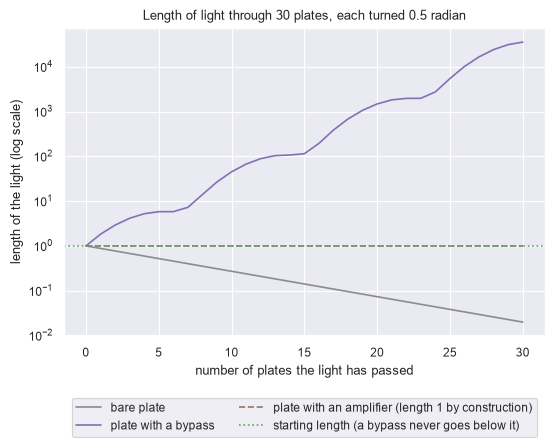

In [5]:
TURN, PLATE_COUNT = 0.5, 30
plate_axes = [np.array([np.cos(TURN * index), np.sin(TURN * index)]) for index in range(PLATE_COUNT + 1)]
lengths = {"bare": [1.0], "bypass": [1.0], "amplifier": [1.0]}
light_bare, light_bypass, light_amplified = plate_axes[0], plate_axes[0], plate_axes[0]
bypass_never_falls = True
for axis in plate_axes[1:]:
    light_bare = pass_through_plate(axis, light_bare)
    before = np.linalg.norm(light_bypass)
    light_bypass = pass_through_skip_plate(axis, light_bypass)
    bypass_never_falls = bypass_never_falls and np.linalg.norm(light_bypass) >= before - 1e-12
    light_amplified = renormalize(pass_through_plate(axis, light_amplified))
    for name, current in (("bare", light_bare), ("bypass", light_bypass), ("amplifier", light_amplified)):
        lengths[name].append(np.linalg.norm(current))

report("bare length after 30 plates is cos(0.5)^30", np.isclose(lengths["bare"][-1], np.cos(TURN) ** PLATE_COUNT, rtol=1e-9),
       f"measured {lengths['bare'][-1]:.2e}, predicted {np.cos(TURN) ** PLATE_COUNT:.2e}")
report("bypass length never falls, and grows", bypass_never_falls and lengths["bypass"][-1] > 1,
       f"length after 30 plates {lengths['bypass'][-1]:.3e}")
print(f"[by construction, cannot fail] amplified length is 1 after every plate (largest deviation {np.abs(np.array(lengths['amplifier']) - 1).max():.1e}); not counted as evidence")

figure, axes_plot = plt.subplots(figsize=(6.2, 4))
steps = np.arange(PLATE_COUNT + 1)
axes_plot.semilogy(steps, lengths["bare"], color=BEFORE, label="bare plate")
axes_plot.semilogy(steps, lengths["bypass"], color=MODEL, label="plate with a bypass")
axes_plot.semilogy(steps, lengths["amplifier"], color=AMPLIFIER_COLOUR, linestyle="--", label="plate with an amplifier (length 1 by construction)")
axes_plot.axhline(1.0, color=BOUND, linestyle=":", label="starting length (a bypass never goes below it)")
axes_plot.set_xlabel("number of plates the light has passed")
axes_plot.set_ylabel("length of the light (log scale)")
axes_plot.set_title("Length of light through 30 plates, each turned 0.5 radian")
axes_plot.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
save_figure(figure, "31-light-through-plates")
plt.show()

## Claim 4: a residual layer's slope is between `1 - slope` and `1 + slope` (`lipschitzWith_addSkip`, `le_dist_addSkip`, `addSkip_injective`)

A layer `input + branch(input)` with a branch of slope at most 0.5 stretches every gap by at most 1.5 and at least 0.5.
Branch: `0.5 * tanh(orthogonal @ input)` in 6 dimensions. Prediction (what can be checked): over 20000 random pairs (a third of them very close
together), the ratio of output gap to input gap stays inside `[0.5, 1.5]`. The notebook also prints how close the
ratio came to each end; it need not reach either end. What would count against it: any ratio outside. The control
breaks the hypothesis: the branch `-2 * |input|` in one dimension has slope 2. Over 20000 random pairs of inputs
in `[-2, 2]`, the smallest ratio should fall far below the lower bound's 0.5 (below 0.05); if the layer kept
points apart it would stay above 0.5. The pair `1` and `-1/3` is a hand example of a merge.

In [6]:
SLOPE = 0.5
orthogonal = make_random_orthogonal(6)
def branch(state):
    return SLOPE * np.tanh(orthogonal @ state)

ratios = []
for trial in range(20000):
    first = generator.standard_normal(6) * generator.uniform(0.05, 2)
    close = trial % 3 == 0
    step = generator.standard_normal(6)
    step = step / np.linalg.norm(step) * (1e-7 if close else generator.uniform(0.01, 3))
    second = first + step
    gap_after = np.linalg.norm(add_skip(branch, first) - add_skip(branch, second))
    ratios.append(gap_after / np.linalg.norm(step))
ratios = np.array(ratios)
print(f"{len(ratios)} random pairs, a third of them very close together")
report("every gap ratio lies in [1 - 0.5, 1 + 0.5]", ratios.min() >= 1 - SLOPE - 1e-6 and ratios.max() <= 1 + SLOPE + 1e-6,
       f"measured range [{ratios.min():.3f}, {ratios.max():.3f}]")
print(f"closest to the lower bound 0.5: {ratios.min():.3f} (margin {ratios.min() - (1 - SLOPE):.3f}); closest to the upper bound 1.5: {ratios.max():.3f} (margin {(1 + SLOPE) - ratios.max():.3f})")

def fold_branch(state):
    return -2.0 * np.abs(state)
merged_gap = abs(add_skip(fold_branch, np.array([1.0])) - add_skip(fold_branch, np.array([-1.0 / 3]))).item()
print(f"[by construction, cannot fail] hand example: inputs 1 and -1/3 under the slope-2 branch have output gap {merged_gap:.1e}; not counted as evidence")
fold_ratios = []
for trial in range(20000):
    first_input, second_input = generator.uniform(-2, 2, 2)
    fold_gap = abs(add_skip(fold_branch, np.array([first_input])) - add_skip(fold_branch, np.array([second_input]))).item()
    fold_ratios.append(fold_gap / abs(first_input - second_input))
report("control: with a branch of slope 2, random pairs include ones nearly merged (ratio under 0.05, far below 0.5)",
       min(fold_ratios) < 0.05, f"smallest ratio over 20000 random pairs {min(fold_ratios):.4f}")

20000 random pairs, a third of them very close together
[PASS] every gap ratio lies in [1 - 0.5, 1 + 0.5]  (measured range [0.564, 1.467])
closest to the lower bound 0.5: 0.564 (margin 0.064); closest to the upper bound 1.5: 1.467 (margin 0.033)
[by construction, cannot fail] hand example: inputs 1 and -1/3 under the slope-2 branch have output gap 0.0e+00; not counted as evidence
[PASS] control: with a branch of slope 2, random pairs include ones nearly merged (ratio under 0.05, far below 0.5)  (smallest ratio over 20000 random pairs 0.0004)


True

## Claim 5: depth does not blow up the slope (`dist_runResidualLayers_le_exp`)

Share a slope budget `exponent = 2` equally among `layer_count` branches, each of slope `2 / layer_count`, in 6
dimensions. The stack stretches any gap by at most `e^2 = 7.389`. Prediction: for layer counts 1 to 512 the largest
measured stretch stays below `e^2`. Two stacks: **aligned**, where each branch is `slope * tanh(input)` and two inputs
very close to 0 are stretched by about `(1 + 2/layer_count)^layer_count` (the chapter's per-layer product, which approaches `e^2`
from below), and **random**, where each branch uses its own random orthogonal matrix and 200 random close pairs are tried.
The **plain** stack (no skip) is `slope * tanh(orthogonal @ input)` composed: the chapter says its stretch is a power of a number
far below one. The control breaks the hypothesis: branch slopes of `3 / layer_count` (1.5 times the budget), where
the aligned stretch should approach `e^3 = 20.1` and pass `e^2`. What would count against the claim: any skip stack
above `e^2`.

[PASS] skip stacks (aligned and random) never stretch past e^2 at any depth up to 512  (largest stretch 7.360 against e^2 = 7.389)
[PASS] aligned stretch equals the per-layer product (1 + 2/layer_count)^layer_count to 1e-3 relative  (at 512 layers 7.360 against 7.360)
[PASS] plain stack's stretch keeps falling with depth, measured where it does not underflow, and ends below 1e-6  (at 8 layers 1.53e-05; at 64 layers 4.68e-97; 3 deeper depths underflow to 0 in float64 and are not used)
[PASS] control: branch slopes of 1.5 times the budget break the bound e^2  (stretch 19.91 at 512 layers, 2.69 times e^2)


wrote book/figures/31-stretch-against-depth.png


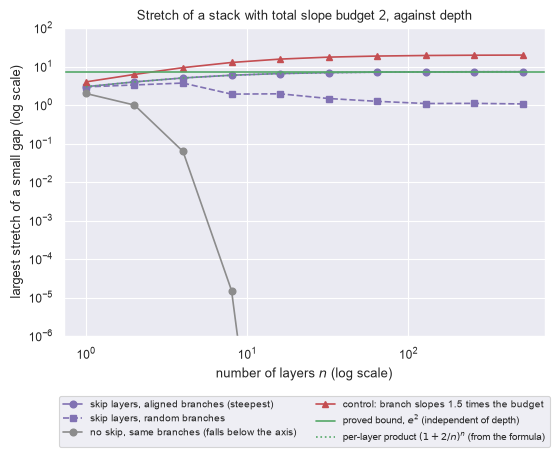

In [7]:
EXPONENT, DIMENSION, GAP = 2.0, 6, 1e-7
LAYER_COUNTS = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]

def run_stack(branches, state, skip):
    for branch_of_layer in branches:
        state = state + branch_of_layer(state) if skip else branch_of_layer(state)
    return state

def make_branches(layer_count, slope, aligned):
    def make_branch(matrix):
        return lambda state: slope * np.tanh(matrix @ state)
    return [make_branch(np.eye(DIMENSION) if aligned else make_random_orthogonal(DIMENSION)) for layer in range(layer_count)]

def measure_stretch(branches, skip, pair_count):
    largest = 0.0
    for pair in range(pair_count):
        first = generator.standard_normal(DIMENSION) * 1e-3
        step = make_unit(generator.standard_normal(DIMENSION)) * GAP
        gap_after = np.linalg.norm(run_stack(branches, first, skip) - run_stack(branches, first + step, skip))
        largest = max(largest, gap_after / GAP)
    return largest

stretch = {name: [] for name in ("aligned skip", "random skip", "plain", "control")}
for layer_count in LAYER_COUNTS:
    slope = EXPONENT / layer_count
    stretch["aligned skip"].append(measure_stretch(make_branches(layer_count, slope, True), True, 3))
    stretch["random skip"].append(measure_stretch(make_branches(layer_count, slope, False), True, 200))
    stretch["plain"].append(measure_stretch(make_branches(layer_count, slope, False), False, 200))
    stretch["control"].append(measure_stretch(make_branches(layer_count, 1.5 * slope, True), True, 3))
per_layer_product = [(1 + EXPONENT / layer_count) ** layer_count for layer_count in LAYER_COUNTS]
growth_limit = np.exp(EXPONENT)

report("skip stacks (aligned and random) never stretch past e^2 at any depth up to 512",
       max(max(stretch["aligned skip"]), max(stretch["random skip"])) <= growth_limit,
       f"largest stretch {max(max(stretch['aligned skip']), max(stretch['random skip'])):.3f} against e^2 = {growth_limit:.3f}")
report("aligned stretch equals the per-layer product (1 + 2/layer_count)^layer_count to 1e-3 relative",
       np.allclose(stretch["aligned skip"], per_layer_product, rtol=1e-3),
       f"at 512 layers {stretch['aligned skip'][-1]:.3f} against {per_layer_product[-1]:.3f}")
plain_measured = [(count, value) for count, value in zip(LAYER_COUNTS, stretch["plain"]) if value > 0]
plain_falls = all(later[1] < earlier[1] for earlier, later in zip(plain_measured, plain_measured[1:]))
report("plain stack's stretch keeps falling with depth, measured where it does not underflow, and ends below 1e-6",
       plain_falls and plain_measured[-1][1] < 1e-6,
       f"at 8 layers {stretch['plain'][3]:.2e}; at {plain_measured[-1][0]} layers {plain_measured[-1][1]:.2e}; "
       f"{len(LAYER_COUNTS) - len(plain_measured)} deeper depths underflow to 0 in float64 and are not used")
report("control: branch slopes of 1.5 times the budget break the bound e^2",
       stretch["control"][-1] > growth_limit,
       f"stretch {stretch['control'][-1]:.2f} at 512 layers, {stretch['control'][-1] / growth_limit:.2f} times e^2")

figure, axes_plot = plt.subplots(figsize=(6.2, 4))
axes_plot.loglog(LAYER_COUNTS, stretch["aligned skip"], color=MODEL, marker="o", label="skip layers, aligned branches (steepest)")
axes_plot.loglog(LAYER_COUNTS, stretch["random skip"], color=MODEL, marker="s", linestyle="--", label="skip layers, random branches")
plain_layers = [count for count, value in zip(LAYER_COUNTS, stretch["plain"]) if value > 0]    # beyond these the stretch underflows to 0 in float64
plain_values = [value for value in stretch["plain"] if value > 0]
axes_plot.loglog(plain_layers, plain_values, color=BEFORE, marker="o", label="no skip, same branches (falls below the axis)")
axes_plot.loglog(LAYER_COUNTS, stretch["control"], color=CONTROL_COLOUR, marker="^", label="control: branch slopes 1.5 times the budget")
axes_plot.axhline(growth_limit, color=BOUND, label="proved bound, $e^{2}$ (independent of depth)")
axes_plot.loglog(LAYER_COUNTS, per_layer_product, color=BOUND, linestyle=":", label="per-layer product $(1 + 2/n)^n$ (from the formula)")
axes_plot.set_xlabel("number of layers $n$ (log scale)")
axes_plot.set_ylabel("largest stretch of a small gap (log scale)")
axes_plot.set_title("Stretch of a stack with total slope budget 2, against depth")
axes_plot.set_ylim(1e-6, 100)    # the plain stack falls far below this; the axis is cut so the bounds can be read
axes_plot.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=7)
save_figure(figure, "31-stretch-against-depth")
plt.show()

## Claim 6: the memory cell of an LSTM is a skip through time (`abs_updateCell_sub`, `updateCell_sub_of_open_gate`)

One step `forget_gate * cell + input_gate * candidate` multiplies the gap between two cells by exactly the forget gate;
with the gate fully open the gap is carried forward unchanged. Prediction: over 50 steps with random input gates and
candidates (the same for both cells), the gap equals the product of the gates to rounding error; with gates fixed at 1 it
is unchanged. The control is a gate of 1.1, outside `[0, 1]`: the gap then grows, so `abs_updateCell_sub_le` needs its hypothesis.

In [8]:
def run_cell(forget_gates, cell, input_gates, candidates):
    for forget_gate, input_gate, candidate in zip(forget_gates, input_gates, candidates):
        cell = forget_gate * cell + input_gate * candidate
    return cell

STEP_COUNT = 50
input_gates = generator.uniform(0, 1, STEP_COUNT)
candidates = generator.uniform(-1, 1, STEP_COUNT)
forget_gates = generator.uniform(0.8, 1.0, STEP_COUNT)
first_cell, second_cell = 0.7, -0.4
gap = abs(run_cell(forget_gates, first_cell, input_gates, candidates) - run_cell(forget_gates, second_cell, input_gates, candidates))
print(f"[by construction, cannot fail] gap after 50 steps {gap:.4f} = |gap before| times the product of the forget gates {abs(first_cell - second_cell) * np.prod(forget_gates):.4f}; the algebra of the update, not counted as evidence")
open_gap = abs(run_cell(np.ones(STEP_COUNT), first_cell, input_gates, candidates) - run_cell(np.ones(STEP_COUNT), second_cell, input_gates, candidates))
print(f"[by construction, cannot fail] with the gate open the gap is carried forward unchanged: {open_gap:.6f} against {abs(first_cell - second_cell):.6f}; not counted as evidence")
wide_gap = abs(run_cell(np.full(STEP_COUNT, 1.1), first_cell, input_gates, candidates) - run_cell(np.full(STEP_COUNT, 1.1), second_cell, input_gates, candidates))
report("control: a forget gate of 1.1 makes the gap grow", wide_gap > 100 * abs(first_cell - second_cell),
       f"gap {wide_gap:.1f} after 50 steps from {abs(first_cell - second_cell):.1f}")

[by construction, cannot fail] gap after 50 steps 0.0037 = |gap before| times the product of the forget gates 0.0037; the algebra of the update, not counted as evidence
[by construction, cannot fail] with the gate open the gap is carried forward unchanged: 1.100000 against 1.100000; not counted as evidence
[PASS] control: a forget gate of 1.1 makes the gap grow  (gap 129.1 after 50 steps from 1.1)


True